In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, GridSearchCV, train_test_split, cross_val_predict, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score, accuracy_score, confusion_matrix
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, ClassifierMixin
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# access the training sets
from dataset import training_set_1, training_set_2, training_set_3

# access the binning function
from redshift_fn import binDataFunc, eta_015

# access the results plotting function
from results import classification_results, plot_classification_scatter

# AdaBoost 1

Original data shape: (1311, 122)

DATA PARTITION
Total sources: 1311
Training sources: 918
Testing sources: 393
Number of classes: 15
Training classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Testing classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Fitting 10 folds for each of 75 candidates, totalling 750 fits

GridSearchCV Results
Best CV accuracy: 0.33659818442427136
Best parameters: {'estimator__max_depth': 3, 'learning_rate': 0.01, 'n_estimators': 1500}

CAdB1 Results
Accuracy: 0.3181

CAdB1 Results:
eta_0.15: 9.9237
eta_2sigma: 5.3435
sigma: 0.1334
sigma_NMAD: 0.0617


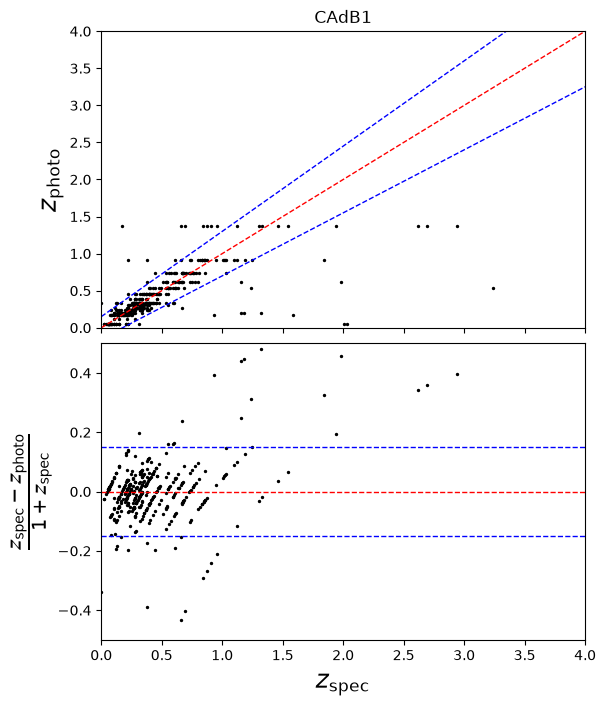

In [8]:
file_path = "/home/sk/Projects/Astrophysics/data/ATLAS.csv"

# Load data and split
X_train, X_test, y_train, y_test, test_indices, y = training_set_1(file_path)

# Create 15 bins
y_all = np.concatenate([y_train, y_test])
y_all_binned, bin_edges, bin_values = binDataFunc(y_all.copy(), 15)

n_train = len(y_train)
y_train_binned = y_all_binned[:n_train]
y_test_binned = y_all_binned[n_train:]

# Convert binned redshifts to integer class labels
y_train_class = np.searchsorted(bin_values, y_train_binned).astype(int)
y_test_class = np.searchsorted(bin_values, y_test_binned).astype(int)

print("Number of classes:", len(bin_values))
print("Training classes:", np.unique(y_train_class))
print("Testing classes:", np.unique(y_test_class))

# AdaBoost
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42
)

param_grid = {
    "n_estimators": [50, 100, 500, 1000, 1500],
    "learning_rate": [0.0001, 0.001, 0.01, 0.1, 1.0],
    "estimator__max_depth": [1, 2, 3]
}

# Stratified 10-fold cross-validation
kfold = StratifiedKFold(
    n_splits=10,
    random_state=10,
    shuffle=True
)

# GridSearchCV based on classification accuracy
grid_search = GridSearchCV(
    estimator=ada,
    param_grid=param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_search.fit(X_train, y_train_class)

# Best model based on CV accuracy
best_model = grid_search.best_estimator_

print("\nGridSearchCV Results")
print("Best CV accuracy:", grid_search.best_score_)
print("Best parameters:", grid_search.best_params_)

# Predict test classes
predicted_class = best_model.predict(X_test)

# Convert predicted classes to representative redshift values
bin_values = np.asarray(bin_values)
y_pred = bin_values[predicted_class]

# Convert to arrays
y_test = np.asarray(y_test, dtype=np.float32)
y_pred = np.asarray(y_pred, dtype=np.float32)

# Classification accuracy
accuracy = np.mean(y_test_class == predicted_class)

print(f"\nCAdB1 Results")
print(f"Accuracy: {accuracy:.4f}")

# Calculate eta_0.15, eta_2sigma, sigma and sigma_NMAD
classification_results(
    y_test,
    y_pred,
    test_name="CAdB1"
)

# Plot classification scatter graph
plot_classification_scatter(
    y_test,
    y_pred,
    title="CAdB1"
)

Original data shape: (1311, 122)

DATA PARTITION
Total sources: 1311
Training sources(ELAIS-S1): 495
Testing sources(CDFS): 816
Number of classes: 15
Training classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Testing classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Fitting 10 folds for each of 75 candidates, totalling 750 fits

GridSearchCV Results
Best CV accuracy: 0.37175510204081635
Best parameters: {'estimator__max_depth': 3, 'learning_rate': 1.0, 'n_estimators': 1000}

CAdB1 Results
Accuracy: 0.2806

CAdB1 Results:
eta_0.15: 10.7843
eta_2sigma: 5.3922
sigma: 0.1392
sigma_NMAD: 0.0677


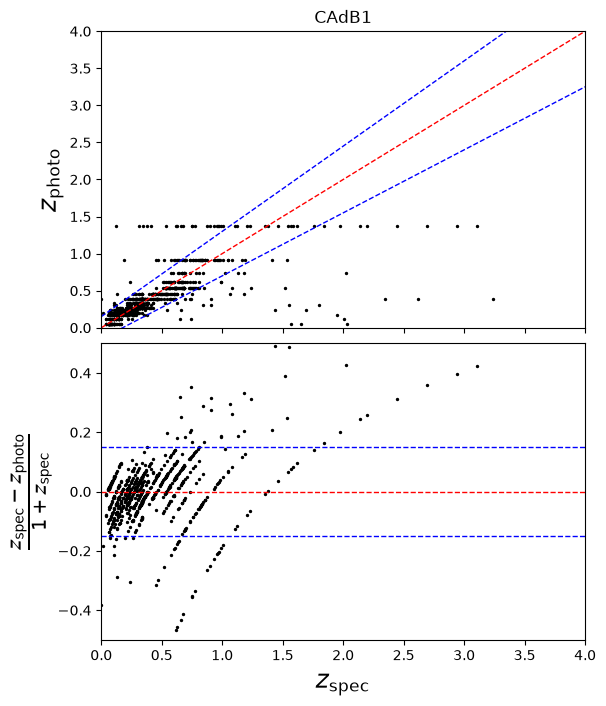

In [10]:
file_path = "/home/sk/Projects/Astrophysics/data/ATLAS.csv"

# Load data and split
X_train, X_test, y_train, y_test = training_set_2(file_path)

# Create 15 bins
y_all = np.concatenate([y_train, y_test])
y_all_binned, bin_edges, bin_values = binDataFunc(y_all.copy(), 15)

n_train = len(y_train)
y_train_binned = y_all_binned[:n_train]
y_test_binned = y_all_binned[n_train:]

# Convert binned redshifts to integer class labels
y_train_class = np.searchsorted(bin_values, y_train_binned).astype(int)
y_test_class = np.searchsorted(bin_values, y_test_binned).astype(int)

print("Number of classes:", len(bin_values))
print("Training classes:", np.unique(y_train_class))
print("Testing classes:", np.unique(y_test_class))

# AdaBoost
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42
)

param_grid = {
    "n_estimators": [50, 100, 500, 1000, 1500],
    "learning_rate": [0.0001, 0.001, 0.01, 0.1, 1.0],
    "estimator__max_depth": [1, 2, 3]
}

# Stratified 10-fold cross-validation
kfold = StratifiedKFold(
    n_splits=10,
    random_state=10,
    shuffle=True
)

# GridSearchCV based on classification accuracy
grid_search = GridSearchCV(
    estimator=ada,
    param_grid=param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_search.fit(X_train, y_train_class)

# Best model based on CV accuracy
best_model = grid_search.best_estimator_

print("\nGridSearchCV Results")
print("Best CV accuracy:", grid_search.best_score_)
print("Best parameters:", grid_search.best_params_)

# Predict test classes
predicted_class = best_model.predict(X_test)

# Convert predicted classes to representative redshift values
bin_values = np.asarray(bin_values)
y_pred = bin_values[predicted_class]

# Convert to arrays
y_test = np.asarray(y_test, dtype=np.float32)
y_pred = np.asarray(y_pred, dtype=np.float32)

# Classification accuracy
accuracy = np.mean(y_test_class == predicted_class)

print(f"\nCAdB1 Results")
print(f"Accuracy: {accuracy:.4f}")

# Calculate eta_0.15, eta_2sigma, sigma and sigma_NMAD
classification_results(
    y_test,
    y_pred,
    test_name="CAdB1"
)

# Plot classification scatter graph
plot_classification_scatter(
    y_test,
    y_pred,
    title="CAdB1"
)

# AdaBoost 2

Original data shape: (1311, 122)

DATA PARTITION
Total sources: 1311
Training sources(ELAIS-S1): 495
Testing sources(CDFS): 816
Number of classes: 15
Training classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Testing classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Fitting 10 folds for each of 75 candidates, totalling 750 fits

GridSearchCV Results
CV accuracy: 0.37175510204081635
CV eta_0.15: 0.39379591836734695
Best parameters: {'estimator__max_depth': 3, 'learning_rate': 1.0, 'n_estimators': 1000}
Accuracy: 0.2806

CAdB2 Results:
eta_0.15: 10.7843
eta_2sigma: 5.3922
sigma: 0.1392
sigma_NMAD: 0.0677


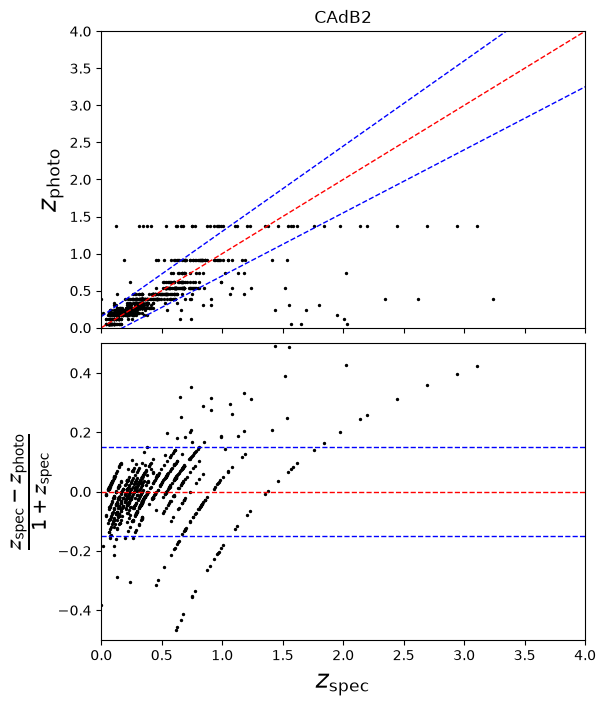

In [4]:
file_path = "/home/sk/Projects/Astrophysics/data/ATLAS.csv"

# Load data and split
X_train, X_test, y_train, y_test = training_set_2(file_path)

# Create 15 bins
y_all = np.concatenate([y_train, y_test])
y_all_binned, bin_edges, bin_values = binDataFunc(y_all.copy(), 15)

n_train = len(y_train)
y_train_binned = y_all_binned[:n_train]
y_test_binned = y_all_binned[n_train:]

# Convert binned redshifts to integer class labels
y_train_class = np.searchsorted(bin_values, y_train_binned).astype(int)
y_test_class = np.searchsorted(bin_values, y_test_binned).astype(int)

print("Number of classes:", len(bin_values))
print("Training classes:", np.unique(y_train_class))
print("Testing classes:", np.unique(y_test_class))

# AdaBoost
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42
)

param_grid = {
    "n_estimators": [50, 100, 500, 1000, 1500],
    "learning_rate": [0.0001, 0.001, 0.01, 0.1, 1.0],
    "estimator__max_depth": [1, 2, 3]
}

# Eta_0.15 scorer
eta015_scorer = make_scorer(eta_015, greater_is_better=False)

# Stratified 10-fold cross-validation
kfold = StratifiedKFold(
    n_splits=10,
    random_state=10,
    shuffle=True
)

# GridSearchCV
grid_search = GridSearchCV(
    estimator=ada,
    param_grid=param_grid,
    cv=kfold,
    scoring={
        "eta015": eta015_scorer,
        "accuracy": "accuracy"
    },
    n_jobs=-1,
    refit="eta015",
    verbose=1
)

grid_search.fit(X_train, y_train_class)

# Best model
best_model = grid_search.best_estimator_

# Best CV results
best_index = grid_search.best_index_

cv_accuracy = grid_search.cv_results_["mean_test_accuracy"][best_index]
cv_eta015 = -grid_search.cv_results_["mean_test_eta015"][best_index]

print("\nGridSearchCV Results")
print("CV accuracy:", cv_accuracy)
print("CV eta_0.15:", cv_eta015)
print("Best parameters:", grid_search.best_params_)

# Predict test classes
predicted_class = best_model.predict(X_test)

# Convert predicted classes to representative redshift values
bin_values = np.asarray(bin_values)
y_pred = bin_values[predicted_class]

# Convert to arrays
y_test = np.asarray(y_test, dtype=np.float32)
y_pred = np.asarray(y_pred, dtype=np.float32)

# Classification accuracy
accuracy = np.mean(y_test_class == predicted_class)

# Final results
print(f"Accuracy: {accuracy:.4f}")
classification_results(y_test, y_pred, test_name="CAdB2")

# plot the classification scatter graphs
plot_classification_scatter(y_test, y_pred, title="CAdB2")

# AdaBoost 3

Original data shape: (1311, 122)

DATA PARTITION
Total sources: 1311
Training sources(CDFS): 816
Testing sources(ELAIS-S1): 495
Number of classes: 15
Training classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Testing classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Fitting 10 folds for each of 75 candidates, totalling 750 fits

GridSearchCV Results
CV accuracy: 0.3125263474856971
CV eta_0.15: 0.4718608852755195
Best parameters: {'estimator__max_depth': 3, 'learning_rate': 1.0, 'n_estimators': 500}
Accuracy: 0.2869

CAdB3 Results:
eta_0.15: 12.9293
eta_2sigma: 5.0505
sigma: 0.1311
sigma_NMAD: 0.0687


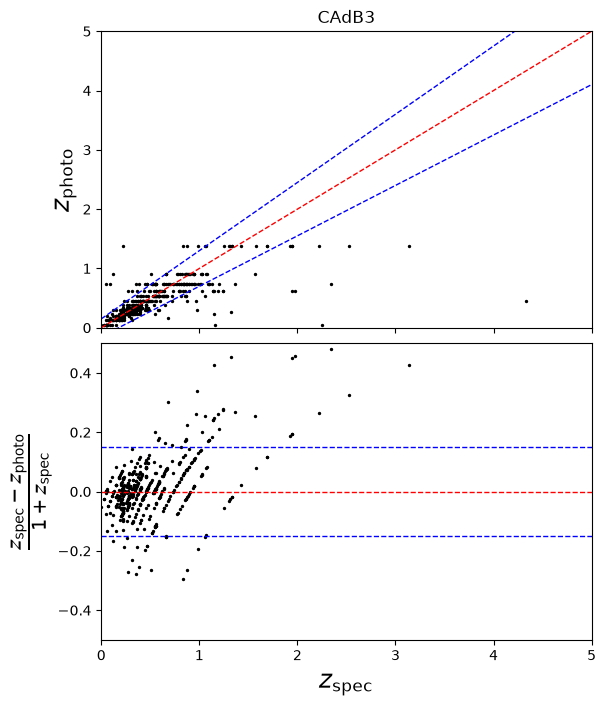

In [5]:
file_path = "/home/sk/Projects/Astrophysics/data/ATLAS.csv"

# Load data and split
X_train, X_test, y_train, y_test = training_set_3(file_path)

# Create 15 bins
y_all = np.concatenate([y_train, y_test])
y_all_binned, bin_edges, bin_values = binDataFunc(y_all.copy(), 15)

n_train = len(y_train)
y_train_binned = y_all_binned[:n_train]
y_test_binned = y_all_binned[n_train:]

# Convert binned redshifts to integer class labels
y_train_class = np.searchsorted(bin_values, y_train_binned).astype(int)
y_test_class = np.searchsorted(bin_values, y_test_binned).astype(int)

print("Number of classes:", len(bin_values))
print("Training classes:", np.unique(y_train_class))
print("Testing classes:", np.unique(y_test_class))

# AdaBoost
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42
)

param_grid = {
    "n_estimators": [50, 100, 500, 1000, 1500],
    "learning_rate": [0.0001, 0.001, 0.01, 0.1, 1.0],
    "estimator__max_depth": [1, 2, 3]
}

# Eta_0.15 scorer
eta015_scorer = make_scorer(eta_015, greater_is_better=False)

# Stratified 10-fold cross-validation
kfold = StratifiedKFold(
    n_splits=10,
    random_state=10,
    shuffle=True
)

# GridSearchCV
grid_search = GridSearchCV(
    estimator=ada,
    param_grid=param_grid,
    cv=kfold,
    scoring={
        "eta015": eta015_scorer,
        "accuracy": "accuracy"
    },
    n_jobs=-1,
    refit="eta015",
    verbose=1
)

grid_search.fit(X_train, y_train_class)

# Best model
best_model = grid_search.best_estimator_

# Best CV results
best_index = grid_search.best_index_

cv_accuracy = grid_search.cv_results_["mean_test_accuracy"][best_index]
cv_eta015 = -grid_search.cv_results_["mean_test_eta015"][best_index]

print("\nGridSearchCV Results")
print("CV accuracy:", cv_accuracy)
print("CV eta_0.15:", cv_eta015)
print("Best parameters:", grid_search.best_params_)

# Predict test classes
predicted_class = best_model.predict(X_test)

# Convert predicted classes to representative redshift values
bin_values = np.asarray(bin_values)
y_pred = bin_values[predicted_class]

# Convert to arrays
y_test = np.asarray(y_test, dtype=np.float32)
y_pred = np.asarray(y_pred, dtype=np.float32)

# Classification accuracy
accuracy = np.mean(y_test_class == predicted_class)

# Final results
print(f"Accuracy: {accuracy:.4f}")
classification_results(y_test, y_pred, test_name="CAdB3")

# plot the classification scatter graphs
plot_classification_scatter(y_test, y_pred, title="CAdB3")

# Verify the binned Z with the original Z

In [6]:
# Check one random training sample
idx = np.random.randint(len(y_train))

print("Random index       :", idx)
print("Original z         :", y_train[idx])
print("Binned z           :", y_train_binned[idx])
print("Assigned class     :", y_train_class[idx])
print("bin_values[class]  :", bin_values[y_train_class[idx]])

print(
    "Correct labeling?  :",
    y_train_binned[idx] == bin_values[y_train_class[idx]]
)

Random index       : 778
Original z         : 0.85992
Binned z           : 0.909825
Assigned class     : 13
bin_values[class]  : 0.909825
Correct labeling?  : True
